# 05 · Test evaluation and error analysis

All modelling decisions were made in notebook 04 with cross-validation. Here the models are retrained on **all 100 training engines** and evaluated **once** on the official FD001 test set. We then look at where they make mistakes:

1. Official benchmark: RUL at the last observed cycle of each test engine (section 2)
2. Error by **early versus late degradation stage**, as the brief requires (section 3)
3. What the model relies on (SHAP, section 5)
4. Where fixed-window features fall short, which motivates the sequence models of Phase 2 (section 6)

In [1]:
import sys
from pathlib import Path

# Make the project folder importable (works from notebooks/ locally and on Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json
import shap

from src.config import RUL_CAP, RESULTS_DIR
from src.data import load_cmapss, add_train_rul, add_test_rul
from src.evaluation import summarize, errors_by_stage, bootstrap_rmse, rmse, STAGES
from src.features import FeatureBuilder
from src.models import MODEL_NAMES, DEFAULT_PARAMS, make_model
from src.plotting import set_style, save, MODEL_COLORS, BLUE, ORANGE, AQUA, YELLOW, VIOLET, GREY, INK

set_style()

train, test, rul = load_cmapss("FD001")
train, test = add_train_rul(train), add_test_rul(test, rul)
best_params = json.loads((RESULTS_DIR / "best_params.json").read_text())

## 1. Final training

The `FeatureBuilder` is now fitted on all training engines, and the same fitted object transforms the test engines. Each model is trained on the capped target (cap 125, chosen in notebook 04) in three variants:

- **raw sensors, default hyperparameters**: the baseline representation
- **engineered features, default hyperparameters**: isolates the effect of feature engineering
- **engineered features, tuned hyperparameters**: the final models

In [2]:
fb = FeatureBuilder().fit(train)
X_train, X_test = fb.transform(train), fb.transform(test)
y_train = train.loc[X_train.index, "RUL"].clip(upper=RUL_CAP).to_numpy()
RAW = fb.groups["sensors"]
ALL = fb.feature_names

variants = {"raw / default": (RAW, "default"), "engineered / default": (ALL, "default"),
            "engineered / tuned": (ALL, "tuned")}
models, preds = {}, {}
test_rows = X_test.assign(true_rul=test.loc[X_test.index, "RUL"].to_numpy())

preds[("Mean baseline", "-")] = np.full(len(X_test), y_train.mean())
for name in ["elastic_net", "random_forest", "xgboost"]:
    for variant, (fs, p) in variants.items():
        params = DEFAULT_PARAMS[name] if p == "default" else best_params[name]
        model = make_model(name, **params).fit(X_train[fs], y_train)
        models[(MODEL_NAMES[name], variant)] = model
        preds[(MODEL_NAMES[name], variant)] = np.clip(model.predict(X_test[fs]), 0, None)

pred_df = pd.DataFrame({f"{m} | {v}": p for (m, v), p in preds.items()}, index=X_test.index)
print(f"trained {len(models)} models; predictions for {len(X_test):,} test cycles")

trained 9 models; predictions for 13,096 test cycles


## 2. Official benchmark: last observed cycle

The standard FD001 evaluation uses one prediction per test engine, at its last observed cycle, compared with `RUL_FD001.txt`. We score against the **true RUL**. The test labels only go up to 145, so the cap has little effect here, but the brief asks us to cap only where justified, so we do not cap the ground truth. The 95% confidence interval comes from bootstrapping over the 100 engines.

In [3]:
is_last = test_rows.groupby("unit")["cycle"].transform("max") == test_rows["cycle"]
y_last = test_rows.loc[is_last, "true_rul"].to_numpy()

rows = []
for (m, v), p in preds.items():
    p_last = p[is_last.to_numpy()]
    lo, hi = bootstrap_rmse(y_last, p_last)
    rows.append({"model": m, "variant": v, **summarize(y_last, p_last), "RMSE 95% CI": f"{lo:.1f} - {hi:.1f}",
                 "RMSE vs capped truth": rmse(np.minimum(y_last, RUL_CAP), p_last)})
benchmark = pd.DataFrame(rows).set_index(["model", "variant"])
benchmark.to_csv(RESULTS_DIR / "test_benchmark.csv")
benchmark.round(2)

RMSE    MAE     Score  RMSE 95% CI  \
model         variant                                                     
Mean baseline -                     43.07  35.90  33629.23  38.7 - 47.5   
Elastic Net   raw / default         21.90  17.62   1286.27  19.0 - 24.7   
              engineered / default  16.73  13.65    432.46  14.6 - 18.7   
              engineered / tuned    16.78  13.69    429.09  14.7 - 18.7   
Random Forest raw / default         18.07  13.19    828.85  14.9 - 20.9   
              engineered / default  12.12   8.91    204.37  10.1 - 14.1   
              engineered / tuned    11.91   8.79    196.93   9.9 - 13.9   
XGBoost       raw / default         18.19  12.93    962.88  14.9 - 21.2   
              engineered / default  11.15   8.23    173.19   9.5 - 12.9   
              engineered / tuned    10.75   8.09    161.11   9.1 - 12.4   

                                    RMSE vs capped truth  
model         variant                                     
Mean baseline -                                    41.94  
Elastic Net   raw / default                        20.80  
              engineered / default                 15.45  
              engineered / tuned                   15.46  
Random Forest raw / default                        17.05  
              engineered / default                 10.82  
              engineered / tuned                   10.67  
XGBoost       raw / default                        17.23  
              engineered / default                 10.03  
              engineered / tuned                    9.69

**Results on the 100 official test engines (last cycle, true RUL):**

- The final **XGBoost** model reaches **RMSE 10.75** (95% CI 9.1 to 12.4), MAE 8.1 and a NASA score of 161. Random Forest follows at 11.9, and Elastic Net at 16.8.
- **Feature engineering is the main driver.** XGBoost improves from 18.2 on raw sensors to 11.2 with engineered features (−39%), and to 10.75 after tuning. Random Forest goes from 18.1 to 11.9 and Elastic Net from 21.9 to 16.8. The confidence intervals of the raw and engineered versions do not overlap, so the gain is not due to chance.
- Tuning adds only about 0.4 cycles for XGBoost and changes nothing for Elastic Net, confirming the conclusion from notebook 04.
- The NASA score drops even more sharply (963 → 161 for XGBoost). The asymmetric score is dominated by large late predictions, and the engineered features remove most of them (section 3).
- The test RMSE (10.75) is close to the cross-validation estimate (9.26 on all cycles against the capped target; 9.69 here against the capped truth). The CV protocol gave a realistic estimate, and there is no sign of overfitting to the validation folds.

**Context from the literature.** Published FD001 results, as collected by Li et al. (2018). Evaluation details such as how the test labels are capped differ between papers, so the comparison is indicative only:

| Method | FD001 RMSE |
|---|---|
| Multi-layer perceptron (as reported by Babu et al., 2016) | 37.56 |
| Support vector regression (as reported by Babu et al., 2016) | 20.96 |
| Relevance vector regression (as reported by Babu et al., 2016) | 23.80 |
| CNN, Babu et al. (2016) | 18.45 |
| LSTM, Zheng et al. (2017) | 16.14 |
| Deep CNN, Li et al. (2018) | 12.61 |

Our best classical model (RMSE 10.75) is better than the published LSTM and CNN baselines on FD001, and in the same range as the deep CNN of Li et al. (2018). We do not claim our model is better than deep learning in general: the papers differ in preprocessing and evaluation details, and our confidence interval (9.1 to 12.4) is wide. What the comparison does show is that **carefully engineered degradation features give a strong baseline**, which the Phase 2 sequence models will have to beat.

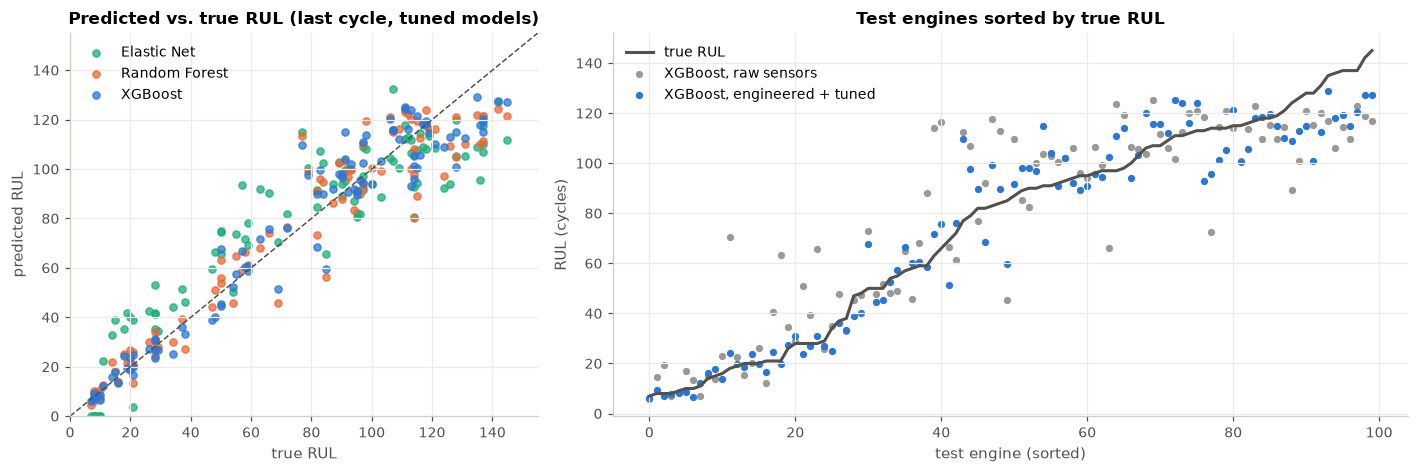

In [4]:
final = {m: preds[(m, "engineered / tuned")][is_last.to_numpy()] for m in ["Elastic Net", "Random Forest", "XGBoost"]}
raw_xgb = preds[("XGBoost", "raw / default")][is_last.to_numpy()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.7]})
for m, p in final.items():
    axes[0].scatter(y_last, p, s=22, alpha=0.75, color=MODEL_COLORS[m], label=m)
lim = [0, max(y_last.max(), max(p.max() for p in final.values())) + 10]
axes[0].plot(lim, lim, color=INK, lw=1, ls="--")
axes[0].set(xlim=lim, ylim=lim, title="Predicted vs. true RUL (last cycle, tuned models)",
            xlabel="true RUL", ylabel="predicted RUL")
axes[0].legend()

order = np.argsort(y_last)
xs = np.arange(len(order))
axes[1].plot(xs, y_last[order], color=INK, lw=2, label="true RUL")
axes[1].scatter(xs, raw_xgb[order], s=14, color=GREY, label="XGBoost, raw sensors")
axes[1].scatter(xs, final["XGBoost"][order], s=14, color=BLUE, label="XGBoost, engineered + tuned")
axes[1].set(title="Test engines sorted by true RUL", xlabel="test engine (sorted)", ylabel="RUL (cycles)")
axes[1].legend()
fig.tight_layout()
save(fig, "05_test_predictions")
plt.show()

- Predictions follow the diagonal closely for engines with little life left: for true RUL up to 60 the mean error is about 0 with a spread of about 5 cycles. The spread grows to about 12 cycles for engines with more remaining life, where degradation has only just begun.
- No prediction exceeds about 130. The 8 engines with true RUL above 130 are predicted at about 121 on average, which is the expected effect of training with a cap of 125. These are early (safe) errors.
- On the right, the raw-sensor model (grey) scatters widely around the true curve, while the engineered model (blue) tracks it closely, especially for the most degraded engines on the left.

## 3. Error by degradation stage

The brief asks for errors in early versus late degradation. The official benchmark only has one point per engine, which is too few to split by stage, so we use **every test cycle**. Each cycle's true RUL is known from notebook 01, which gives 13,096 evaluation points. We define three stages by true RUL:

| Stage | True RUL | Meaning |
|---|---|---|
| early | > 125 | healthy phase; the sensors show almost no degradation yet |
| mid | 50 - 125 | degradation visible and progressing |
| late | ≤ 50 | close to failure; errors here matter most |

The `mean error` column shows bias: positive means the model is **late** (over-estimates remaining life), the dangerous direction.

In [5]:
stage_tables = {}
for key in [("XGBoost", "raw / default"), ("XGBoost", "engineered / tuned"),
            ("Random Forest", "engineered / tuned"), ("Elastic Net", "engineered / tuned")]:
    stage_tables[key] = errors_by_stage(test_rows["true_rul"].to_numpy(), preds[key])
stage_df = pd.concat(stage_tables, names=["model", "variant"])
stage_df.to_csv(RESULTS_DIR / "test_error_by_stage.csv")
display(stage_df.round(2))

# In the early stage the models are trained to output the cap, so also score them against it
early = test_rows["true_rul"].to_numpy() > RUL_CAP
pd.Series({f"{m}, {v}": rmse(np.full(early.sum(), RUL_CAP), preds[(m, v)][early]) for (m, v) in stage_tables},
          name="early stage: RMSE vs. capped target").round(2).to_frame()

n   RMSE    MAE  \
model         variant            stage                                       
XGBoost       raw / default      early (RUL > 125)      7952  73.95  62.18   
                                 mid (50 < RUL <= 125)  4258  20.87  15.86   
                                 late (RUL <= 50)        886  28.78  19.25   
              engineered / tuned early (RUL > 125)      7952  68.38  55.92   
                                 mid (50 < RUL <= 125)  4258  12.44   9.60   
                                 late (RUL <= 50)        886   5.70   4.23   
Random Forest engineered / tuned early (RUL > 125)      7952  69.39  57.29   
                                 mid (50 < RUL <= 125)  4258  13.50  10.33   
                                 late (RUL <= 50)        886   7.46   5.38   
Elastic Net   engineered / tuned early (RUL > 125)      7952  72.57  61.35   
                                 mid (50 < RUL <= 125)  4258  15.88  13.09   
                                 late (RUL <= 50)        886  20.34  17.62   

                                                        mean error (pred - true)  
model         variant            stage                                            
XGBoost       raw / default      early (RUL > 125)                        -62.18  
                                 mid (50 < RUL <= 125)                      7.18  
                                 late (RUL <= 50)                          17.08  
              engineered / tuned early (RUL > 125)                        -55.92  
                                 mid (50 < RUL <= 125)                      2.65  
                                 late (RUL <= 50)                           1.95  
Random Forest engineered / tuned early (RUL > 125)                        -57.29  
                                 mid (50 < RUL <= 125)                      2.26  
                                 late (RUL <= 50)                           3.27  
Elastic Net   engineered / tuned early (RUL > 125)                        -61.35  
                                 mid (50 < RUL <= 125)                      3.62  
                                 late (RUL <= 50)                          15.93

,early stage: RMSE vs. capped target
"XGBoost, raw / default",12.29
"XGBoost, engineered / tuned",6.44
"Random Forest, engineered / tuned",7.14
"Elastic Net, engineered / tuned",12.66


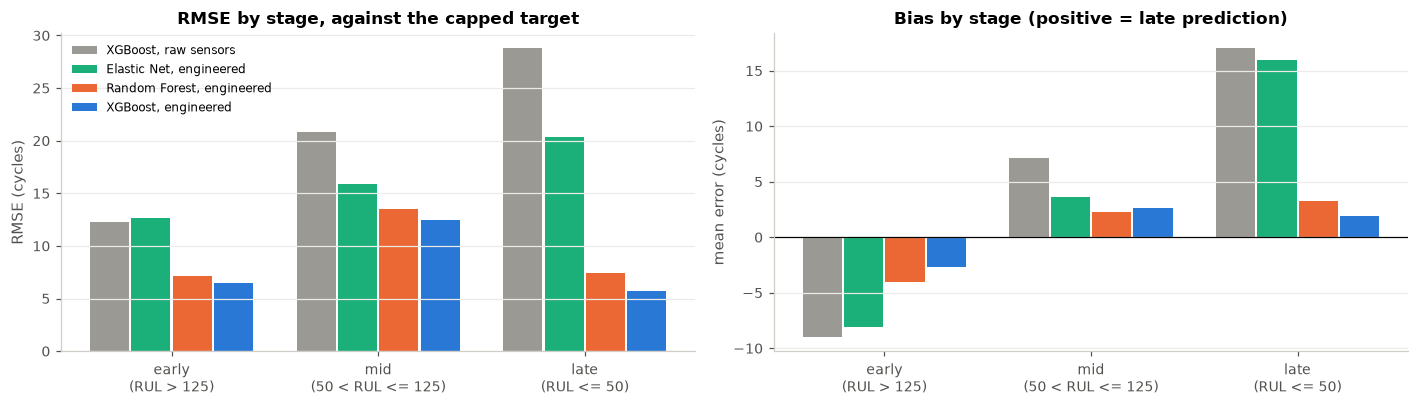

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
stages = list(STAGES)
x = np.arange(len(stages))
entries = [(("XGBoost", "raw / default"), GREY, "XGBoost, raw sensors"),
           (("Elastic Net", "engineered / tuned"), AQUA, "Elastic Net, engineered"),
           (("Random Forest", "engineered / tuned"), ORANGE, "Random Forest, engineered"),
           (("XGBoost", "engineered / tuned"), BLUE, "XGBoost, engineered")]
true_rul = test_rows["true_rul"].to_numpy()
capped = np.minimum(true_rul, RUL_CAP)
for k, (key, color, lab) in enumerate(entries):
    t = errors_by_stage(capped, preds[key], stage_rul=true_rul)
    axes[0].bar(x + (k - 1.5) * 0.2, t["RMSE"], 0.19, color=color, label=lab)
    axes[1].bar(x + (k - 1.5) * 0.2, t["mean error (pred - true)"], 0.19, color=color, label=lab)
for ax, title, yl in [(axes[0], "RMSE by stage, against the capped target", "RMSE (cycles)"),
                      (axes[1], "Bias by stage (positive = late prediction)", "mean error (cycles)")]:
    ax.set_xticks(x, [s.split(" (")[0] + "\n(" + s.split(" (")[1] for s in stages])
    ax.set(title=title, ylabel=yl)
    ax.grid(axis="x", visible=False)
axes[1].axhline(0, color="black", lw=0.8)
axes[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "05_error_by_stage")
plt.show()

The table scores every test cycle against the **true** RUL; the chart scores against the **capped** target the models were trained on (for mid and late stages the two are identical).

- **Late stage (RUL ≤ 50), where errors matter most:** the engineered XGBoost model is very accurate, with RMSE 5.7 and a bias of only +2 cycles. The raw-sensor model has RMSE 28.8 and a bias of **+17 cycles**, meaning it systematically thinks failing engines have more life left than they do. That is the most dangerous kind of error in maintenance. Elastic Net shows the same late bias (+16), because a linear model cannot follow the steep final decline.
- **Mid stage (50-125):** errors are larger (XGBoost RMSE 12.4) because this is where degradation is just becoming visible and engines differ most in how fast they degrade.
- **Early stage (RUL > 125):** against the true RUL every model has a large error (about 70 cycles) and a strong negative bias, but that comes **from the cap, by design**: the models are trained to say "at least 125 cycles left" for healthy engines. Against the capped target, the engineered XGBoost model is off by only 6.4 cycles here (raw: 12.3), so it correctly recognises that these engines are still healthy.

So the error is lowest exactly where it matters most, near failure, and the engineered features cut the late-stage error by about 80% compared with raw sensors.

### 3.1 Predictions along an engine's life

Four test engines with long observed histories, showing how predictions evolve cycle by cycle:

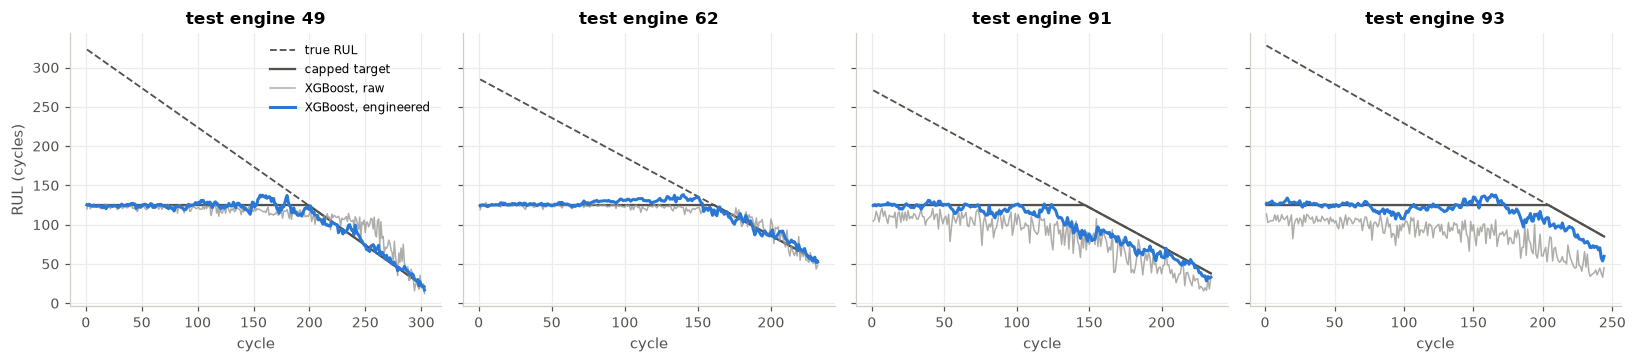

In [7]:
longest = test_rows.groupby("unit")["cycle"].max().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, u in zip(axes, sorted(longest)):
    m = (test_rows["unit"] == u).to_numpy()
    c = test_rows.loc[m, "cycle"]
    ax.plot(c, test_rows.loc[m, "true_rul"], color=INK, ls="--", lw=1.2, label="true RUL")
    ax.plot(c, np.minimum(test_rows.loc[m, "true_rul"], RUL_CAP), color=INK, lw=1.5, label="capped target")
    ax.plot(c, preds[("XGBoost", "raw / default")][m], color=GREY, lw=1, alpha=0.8, label="XGBoost, raw")
    ax.plot(c, preds[("XGBoost", "engineered / tuned")][m], color=BLUE, label="XGBoost, engineered")
    ax.set(title=f"test engine {u}", xlabel="cycle")
axes[0].set_ylabel("RUL (cycles)")
axes[0].legend(fontsize=8)
fig.tight_layout()
save(fig, "05_test_trajectories")
plt.show()

- During the healthy phase both models predict close to 125. As degradation begins, the engineered model (blue) follows the capped target smoothly, while the raw-sensor model (grey) jumps around from cycle to cycle because each prediction rests on single noisy readings.
- Engines 91 and 93 show a typical failure case: their sensors start to drift earlier than their actual remaining life suggests, so the prediction leaves 125 too soon and stays below the target (an early, conservative error of 20 to 30 cycles). Engines 49 and 62 are tracked almost perfectly. Differences in degradation *timing* between engines are a recurring theme in section 5.

## 4. Interpretability: what does XGBoost rely on?

We use SHAP values (Lundberg & Lee, 2017). For each prediction, they split the difference between the model's output and its average output into a contribution from each feature, based on Shapley values from game theory. For tree ensembles they can be computed exactly and quickly (TreeSHAP). We compute them for the final XGBoost model on all test cycles.

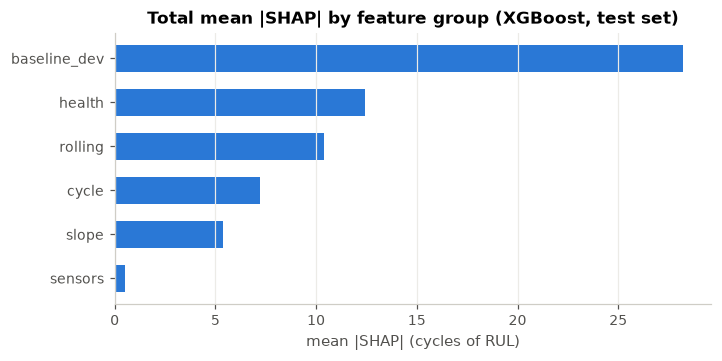

,mean |SHAP|,group
feature,,
health_slope30,9.05,health
cycle,7.21,cycle
s_11_dev,5.42,baseline_dev
s_4_dev,4.44,baseline_dev
s_15_dev,2.61,baseline_dev
s_21_dev,2.45,baseline_dev
s_12_dev,2.43,baseline_dev
s_8_dev,2.05,baseline_dev
s_9_dev,1.99,baseline_dev


In [8]:
xgb_final = models[("XGBoost", "engineered / tuned")]
explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer.shap_values(X_test[ALL])

group_of = {c: g for g, cols in fb.groups.items() for c in cols}
importance = pd.DataFrame({"feature": ALL, "mean |SHAP|": np.abs(shap_values).mean(axis=0)})
importance["group"] = importance["feature"].map(group_of)
group_importance = importance.groupby("group")["mean |SHAP|"].sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(group_importance.index, group_importance.values, color=BLUE, height=0.6)
ax.set(title="Total mean |SHAP| by feature group (XGBoost, test set)", xlabel="mean |SHAP| (cycles of RUL)")
ax.grid(axis="y", visible=False)
save(fig, "05_shap_groups")
plt.show()

importance.sort_values("mean |SHAP|", ascending=False).head(10).round(2).set_index("feature")

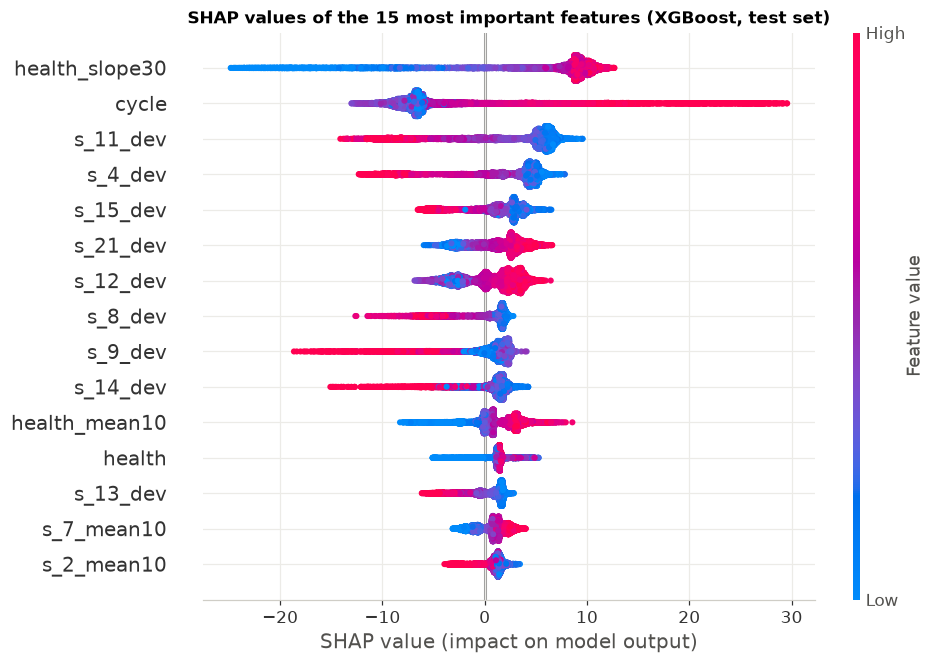

In [9]:
plt.figure()
shap.summary_plot(shap_values, X_test[ALL], max_display=15, show=False, plot_size=(9, 6))
fig = plt.gcf()
fig.axes[0].set_title("SHAP values of the 15 most important features (XGBoost, test set)")
save(fig, "05_shap_summary")
plt.show()

- By group, the **baseline deviations** carry by far the largest total attribution, followed by the health-index features, the rolling means and the cycle count. The plain sensor readings contribute almost nothing once the engineered versions are available. This agrees with the ablation in notebook 04.
- The single most important feature is **`health_slope30`**, the 30-cycle trend of the health index. A strongly negative slope (blue dots, fast decline) pushes the prediction down by up to about 25 cycles.
- The deviations of `s_11` (static pressure Ps30) and `s_4` (LPT outlet temperature T50) come next, the same sensors that ranked highest on the prognostic metrics in notebook 02. A large deviation from the engine's baseline (red) lowers the predicted RUL. For `s_9`/`s_14` (core speeds), only some engines show large deviations, but when they do, the effect is strong.
- **`cycle` behaves in a way that is not obvious at first:** a *high* cycle count pushes the prediction *up*. The model sees cycle together with the degradation features. For the same amount of measured degradation, an engine that took longer to get there is degrading slowly, so it probably has more life left. The model uses age to estimate the *rate* of degradation, something no single feature measures directly.

## 5. Where do fixed-window features fall short?

The brief's hypothesis for Phase 2 is that *fixed rolling features may miss long degradation trajectories and interactions whose timing differs across engines*. We test it with the out-of-fold CV predictions from notebook 04 (every training engine predicted by a model that never saw it) and with the test set.

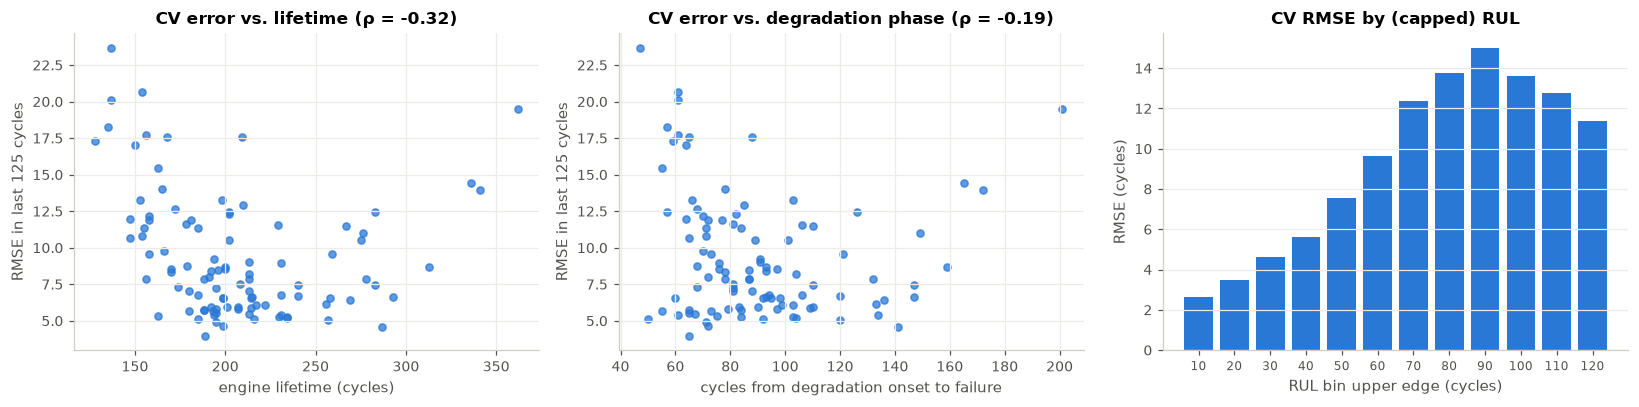

mean error (pred - target) in the last 125 cycles, engines living < 160 cycles: +9.9
mean error (pred - target) in the last 125 cycles, all other engines:           -0.3


,rmse,lifetime,degradation phase length
unit,,,
70,23.7,137,47.0
77,20.7,154,61.0
57,20.1,137,61.0
69,19.5,362,201.0
91,18.2,135,57.0


In [10]:
oof = pd.read_csv(RESULTS_DIR / "cv_oof_predictions.csv")
oof = oof[oof["model"] == "XGBoost"].copy()
oof["target"] = oof["true_rul"].clip(upper=RUL_CAP)
oof["err"] = oof["pred"] - oof["target"]

lifetime = train.groupby("unit")["cycle"].max()
per_engine = (oof[oof["true_rul"] <= RUL_CAP].groupby("unit")
              .apply(lambda g: rmse(g["target"], g["pred"])).rename("rmse").to_frame())
per_engine["lifetime"] = lifetime

# When does each engine visibly start to degrade? First cycle where its smoothed health
# index falls 1.5 units below its own early-life level.
hi = X_train[["unit", "cycle", "health_mean10"]].copy()
base = hi[hi["cycle"] <= 30].groupby("unit")["health_mean10"].mean()
below = hi[hi["health_mean10"] < hi["unit"].map(base) - 1.5]
onset_cycle = below.groupby("unit")["cycle"].min()
per_engine["degradation phase length"] = lifetime - onset_cycle

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, xl in [(axes[0], "lifetime", "engine lifetime (cycles)"),
                    (axes[1], "degradation phase length", "cycles from degradation onset to failure")]:
    ax.scatter(per_engine[col], per_engine["rmse"], s=22, color=BLUE, alpha=0.75)
    rho = per_engine[[col, "rmse"]].corr(method="spearman").iloc[0, 1]
    ax.set(title=f"CV error vs. {'lifetime' if col == 'lifetime' else 'degradation phase'} (ρ = {rho:.2f})",
           xlabel=xl, ylabel="RMSE in last 125 cycles")

bins = np.arange(0, 130, 10)
oof["rul_bin"] = pd.cut(oof["true_rul"].clip(upper=RUL_CAP), bins=bins, include_lowest=True)
by_bin = oof.groupby("rul_bin", observed=True)["err"].agg(lambda e: np.sqrt(np.mean(e ** 2)))
axes[2].bar(range(len(by_bin)), by_bin.values, color=BLUE)
axes[2].set_xticks(range(len(by_bin)), [str(int(b.right)) for b in by_bin.index], fontsize=8)
axes[2].set(title="CV RMSE by (capped) RUL", xlabel="RUL bin upper edge (cycles)", ylabel="RMSE (cycles)")
axes[2].grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "05_gap_analysis")
plt.show()

bias = oof[oof["true_rul"] <= RUL_CAP].groupby("unit")["err"].mean()
short_lived = lifetime < 160
print(f"mean error (pred - target) in the last 125 cycles, engines living < 160 cycles: {bias[short_lived].mean():+.1f}")
print(f"mean error (pred - target) in the last 125 cycles, all other engines:           {bias[~short_lived].mean():+.1f}")
per_engine.sort_values("rmse", ascending=False).head(5).round(1)

The out-of-fold predictions show where the feature-based approach struggles:

1. **Short-lived, fast-degrading engines.** Per-engine error falls as lifetime grows (Spearman ρ = −0.32), and engines that fail before 160 cycles are predicted **late by about 10 cycles on average**, against roughly zero bias for the others. The model partly relies on `cycle` as a prior for "typical" life. An engine that degrades unusually fast gets an optimistic estimate until its sensors have drifted far enough to override that prior.
2. **The onset region.** Error peaks for RUL between about 70 and 110 cycles. Here degradation has started but is still small compared with the noise. A 10- or 30-cycle window sees only a short piece of a slow drift, so the model cannot tell reliably whether the decline has begun.
3. **Unusual trajectories.** Engine 69 (the longest-lived, 362 cycles, with a degradation phase of about 200 cycles) is among the worst. Its slow, drawn-out decline looks unlike the typical engine within any fixed window.

These are exactly the limitations the brief anticipates: *fixed rolling features miss long degradation trajectories and differences in timing between engines*. A sequence model that reads the whole recent history (an LSTM or temporal CNN over windows of 30 to 50+ cycles) can learn the shape and rate of the trajectory directly, instead of relying on hand-picked window lengths and an age prior. Testing that is the goal of Phase 2.

In [11]:
obs = test_rows.groupby("unit")["cycle"].max()
abs_err = pd.Series(np.abs(final["XGBoost"] - y_last), index=test_rows.loc[is_last, "unit"].to_numpy())
short = obs[obs < 60].index
print(f"test engines with < 60 observed cycles: {len(short)}")
print(f"  mean absolute error, short histories : {abs_err[short].mean():.1f} cycles")
print(f"  mean absolute error, the other engines: {abs_err.drop(short).mean():.1f} cycles")

test engines with < 60 observed cycles: 12
  mean absolute error, short histories : 10.7 cycles
  mean absolute error, the other engines: 7.7 cycles


Test engines observed for fewer than 60 cycles have a higher error (MAE 10.7 against 7.7). With a short history, the 30-cycle slope and the health-index trend have barely started, and these engines also tend to have more remaining life, where prediction is inherently harder. This is a further case where fixed windows run out of information.

In [12]:
final_table = benchmark.loc[[("Mean baseline", "-")] + [(m, "engineered / tuned") for m in final]]
final_table.to_csv(RESULTS_DIR / "test_final_models.csv")
pd.DataFrame({"unit": test_rows.loc[is_last, "unit"].to_numpy(), "true_rul": y_last,
              **{f"pred_{m.lower().replace(' ', '_')}": p for m, p in final.items()}}
             ).to_csv(RESULTS_DIR / "test_predictions_last_cycle.csv", index=False)
final_table.round(2)

,,RMSE,MAE,Score,RMSE 95% CI,RMSE vs capped truth
model,variant,,,,,
Mean baseline,-,43.07,35.90,33629.23,38.7 - 47.5,41.94
Elastic Net,engineered / tuned,16.78,13.69,429.09,14.7 - 18.7,15.46
Random Forest,engineered / tuned,11.91,8.79,196.93,9.9 - 13.9,10.67
XGBoost,engineered / tuned,10.75,8.09,161.11,9.1 - 12.4,9.69


## Summary of Phase 1

| | Elastic Net | Random Forest | **XGBoost** |
|---|---|---|---|
| Test RMSE, raw sensors | 21.9 | 18.1 | 18.2 |
| Test RMSE, engineered + tuned | 16.8 | 11.9 | **10.75** |
| Late-stage RMSE (RUL ≤ 50) | 20.3 | 7.5 | **5.7** |

- **Degradation feature engineering roughly halves the error** for the tree models and removes the dangerous late bias near failure.
- **XGBoost** with engineered features is the best Phase 1 model: test RMSE 10.75 (95% CI 9.1 to 12.4), MAE 8.1, NASA score 161, with errors smallest in the late degradation stage.
- The most useful information is how far each engine has drifted from its **own** early-life state, and how fast its health index is falling.
- **Remaining gap:** fast-degrading engines, the onset of degradation, and engines with short or unusual histories. All three depend on the shape and timing of the full trajectory, which fixed windows capture poorly. They motivate the sequence models (LSTM / temporal CNN) of Phase 2, which should be compared against the 10.75 baseline on exactly this test protocol.